## Objetivos del experimento y alineación con requisitos de negocio (Comprensión del Negocio)

**Definición del Problema a Resolver:**
El problema técnico central consiste en que, dada la imagen de un objeto en una orientación arbitraria proveniente de una línea de producción, el sistema debe ser capaz de determinar:
1. De qué objeto se trata.
2. En qué ángulo de rotación se encuentra.
3. Con qué nivel de confianza realiza ambas predicciones.
4. Si es mecánicamente seguro que el brazo robótico actúe o si se debe rechazar la acción.

**Impacto del Negocio:**
*   **Error de Clase (Identificación):** Provoca el empaque de un producto equivocado, afectando la calidad.
*   **Error de Ángulo (Rotación):** Un fallo fuera de la tolerancia mecánica estricta del robot (±10°) produce un agarre fallido, producto dañado o paradas críticas en la línea de producción.

**Propósito del Diseño:**
Mantener o mejorar el rendimiento (throughput) y la calidad actual operando las 24 horas, eliminando la intervención manual constante, con un TCO menor y garantizando un mecanismo de "Rechazo Seguro" para los casos que el modelo de IA no pueda resolver con absoluta confianza.

---

### Solucion de Capacidades:
- Capacidad 1: Identificación (Requisito 6.1): Resuelto mediante una Máquina de Vectores de Soporte (SVM con Kernel RBF) entrenada sobre características HOG, logrando >98% de exactitud.
- Capacidad 2: Estimación de Ángulo e Incertidumbre (Requisito 6.1): Resuelto formulando el ángulo como un problema de clasificación probabilística multinivel. La incertidumbre se calculó midiendo la entropía de Shannon sobre la distribución de probabilidades de salida del SVM.
- Capacidad 3: Motor de Recuperación Visual Top-k (Requisito 6.1): Resuelto implementando un motor KNN basado en similitud del coseno sobre los mismos vectores HOG.   Criterio de Aceptación (±10° de tolerancia): Se validó midiendo el Error Absoluto Medio Circular. Dado que el acierto mecánico nativo fue del 54.67%, el requisito se cubrió diseñando un sistema de umbrales que bloquea preventivamente las acciones dudosas.   


---
### Diccionario de Datos (COIL-100)
El dataset original utilizado para esta fase de experimentación es COIL-100 (Columbia Object Image Library), el cual actúa como un entorno controlado para simular la línea de producción.

| Característica | Descripción |
| :--- | :--- |
| **Fuente** | Columbia CAVE / TensorFlow Datasets |
| **Volumen Total** | 7.200 imágenes |
| **Clases (Objetos)** | 100 objetos diferentes |
| **Vistas por Objeto** | 72 vistas por objeto (capturas cada 5° en una rotación de 360°) |
| **Formato y Resolución** | Imágenes RGB, 128x128 píxeles sobre fondo negro uniforme |
| **Estructura de Nombres** | `obj[ID_Clase]__[Ángulo].png` (Ej. `obj1__0.png`) |

## Tabla de Contenido

Este notebook sigue la metodología CRISP-DM y asegura la trazabilidad y reproducibilidad experimental de punta a punta:

*   [1. Introducción y Configuración del Entorno](#1-introducción-y-configuración-del-entorno)
    *   [1.1. Objetivos del experimento y alineación con requisitos de negocio (±10° de tolerancia).](#11-objetivos-del-experimento-y-alineación-con-requisitos-de-negocio)
    *   [1.2. Configuración de librerías, tracking de experimentos y semillas aleatorias.](#12-configuración-de-librerías-tracking-de-experimentos-y-semillas-aleatorias)
*   [2. Fase 1: Comprensión de los Datos (Análisis del Dataset COIL-100)](#2-fase-1-comprensión-de-los-datos-análisis-del-dataset-coil-100)
    *   [2.1. Carga, exploración (EDA) y caracterización estadística del dataset COIL-100.](#21-carga-exploración-eda-y-caracterización-estadística-del-dataset-coil-100)
    *   [2.2. Análisis de dominio: Brecha entre COIL-100 y el entorno real de planta.](#22-análisis-de-dominio-brecha-entre-coil-100-y-el-entorno-real-de-planta)
*   [3. Fase 2: Preparación de Datos y Diseño Experimental](#3-fase-2-preparación-de-datos-y-diseño-experimental)
    *   [3.1. Implementación de los Protocolos de Partición Obligatorios (A, B, C, D).](#31-implementación-de-los-protocolos-de-partición-obligatorios-a-b-c-d)
    *   [3.2. Ingeniería de características (Feature Extraction para ML Clásico - HOG).](#32-ingeniería-de-características-feature-extraction-para-ml-clásico---hog)
*   [4. Fase 3: Modelado](#4-fase-3-modelado)
    *   [4.1. Baselines y Referencia Moderna (Implementación para fines comparativos).](#41-baselines-y-referencia-moderna-implementación-para-fines-comparativos)
    *   [4.2. Modelos de Identificación (Entrenamiento y ajuste de 3 algoritmos clásicos).](#42-modelos-de-identificación-entrenamiento-y-ajuste-de-3-algoritmos-clásicos)
    *   [4.3. Modelos de Estimación de Ángulo (Cálculo del ángulo e incertidumbre).](#43-modelos-de-estimación-de-ángulo-cálculo-del-ángulo-e-incertidumbre)
*   [5. Fase 4: Evaluación y Análisis de Resultados](#5-fase-4-evaluación-y-análisis-de-resultados)
    *   [5.1. Resultados del rendimiento de Identificación y Ángulo por protocolo.](#51-resultados-del-rendimiento-de-identificación-y-ángulo-por-protocolo)
    *   [5.2. Diseño del sistema de Rechazo: Determinación de umbrales para casos dudosos.](#52-diseño-del-sistema-de-rechazo-determinación-de-umbrales-para-casos-dudosos)
    *   [5.3. Análisis de errores y validación de la tolerancia (±10°).](#53-análisis-de-errores-y-validación-de-la-tolerancia-10)
*   [6. Fase 5: Tareas Complementarias y Pipeline de Inferencia](#6-fase-5-tareas-complementarias-y-pipeline-de-inferencia)
    *   [6.1. Implementación del motor de recuperación visual (Top-k imágenes similares).](#61-implementación-del-motor-de-recuperación-visual-top-k-imágenes-similares)
    *   [6.2. Ensamblado del Pipeline de Inferencia Final.](#62-ensamblado-del-pipeline-de-inferencia-final)
*   [7. Cierre y Exportación](#7-cierre-y-exportación)
    *   [7.1. Construcción del Model Card.](#71-construcción-del-model-card)
    *   [7.2. Trazabilidad y Exportación de artefactos serializados.](#72-trazabilidad-y-exportación-de-artefactos-serializados)
*   [9. Experimento final por protocolo (versión corregida – vigente)](#9-experimento-final-por-protocolo-versión-corregida--vigente)


## 1. INTRODUCCIÓN Y CONFIGURACIÓN DEL ENTORNO

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
import warnings

# Suprimir advertencias menores para mantener limpia la consola
warnings.filterwarnings('ignore')

### 1.1. Configuración de Reproducibilidad (Requisito estricto del protocolo)

In [2]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print(f"[*] Reproducibilidad garantizada: Semilla fijada en {SEED}")

[*] Reproducibilidad garantizada: Semilla fijada en 42


### 1.2. Detección de Entorno y Configuración de Rutas

In [3]:
try:
    # Intenta importar el módulo específico de Colab
    from google.colab import drive
    IN_COLAB = True
    print("[*] Entorno detectado: Google Colab")

    # Montar Google Drive
    drive.mount('/content/drive')

    # IMPORTANTE: Ajusta esta ruta dependiendo de dónde guardaste el acceso directo en tu Drive
    # Por ejemplo, si lo pusiste directo en "Mi unidad" y se llama "COIL-100":
    BASE_PATH = '/content/drive/MyDrive/IndraVAG/coil-100'

except ImportError:
    IN_COLAB = False
    print("[*] Entorno detectado: Local (VS Code)")

    # Ruta local en tu máquina Windows
    BASE_PATH = r'C:\IndraVAG\data\coil-100'

print(f"[*] Ruta base de datos configurada: {BASE_PATH}")

[*] Entorno detectado: Local (VS Code)
[*] Ruta base de datos configurada: C:\IndraVAG\data\coil-100


### 1.3. Verificación del Dataset

In [4]:
if os.path.exists(BASE_PATH):
    print("\n[+] ¡Directorio de datos encontrado exitosamente!")

    # Listar imágenes (formato típico de COIL-100 es objX__Y.png)
    # Ejemplo: obj1__0.png (Objeto 1, ángulo 0)
    imagenes = [f for f in os.listdir(BASE_PATH) if f.endswith(('.png', '.jpg', '.ppm'))]

    print(f"[+] Total de imágenes encontradas: {len(imagenes)}")
    if len(imagenes) == 7200:
        print("[+] Dataset completo validado (7200 imágenes).")
    else:
        print("[-] Advertencia: El número de imágenes no es 7200. Revisa la descarga.")
else:
    print(f"\n[-] ERROR: No se encontró el directorio en {BASE_PATH}.")
    print("    Si estás en Colab: Verifica el nombre del acceso directo en tu Drive.")
    print("    Si estás en VS Code: Verifica que descargaste el dataset en C:\\IndraVAG\\data\\COIL-100")


[+] ¡Directorio de datos encontrado exitosamente!
[+] Total de imágenes encontradas: 7200
[+] Dataset completo validado (7200 imágenes).


## 2. FASE 1: COMPRENSIÓN DE LOS DATOS (EDA Y CARACTERIZACIÓN COIL-100)
### 2.1. Carga y Estructuración del Dataset

In [5]:
print("[*] Procesando metadatos de las imágenes...")

data_records = []
for img_name in imagenes:
    # COIL-100 usa el formato obj[Clase]__[Angulo].png
    # Ejemplo: obj1__0.png -> Clase: 1, Ángulo: 0
    try:
        base_name = img_name.split('.')[0]
        obj_part, angle_part = base_name.split('__')
        obj_id = int(obj_part.replace('obj', ''))
        angle = int(angle_part)

        data_records.append({
            'filename': img_name,
            'object_id': obj_id,
            'angle': angle
        })
    except Exception as e:
        continue

df = pd.DataFrame(data_records)

print(f"[+] Metadatos extraídos con éxito. Total registros: {len(df)}")
print(f"[+] Total de objetos únicos (Clases): {df['object_id'].nunique()}")
print(f"[+] Total de ángulos por objeto: {df[df['object_id'] == 1]['angle'].nunique()}")

[*] Procesando metadatos de las imágenes...
[+] Metadatos extraídos con éxito. Total registros: 7200
[+] Total de objetos únicos (Clases): 100
[+] Total de ángulos por objeto: 72


### 2.2. Visualización y Caracterización (Rotación de un objeto)

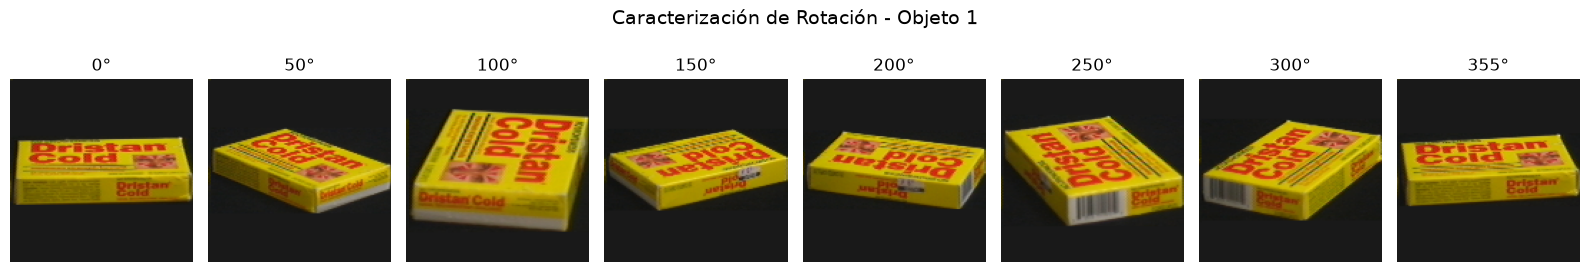

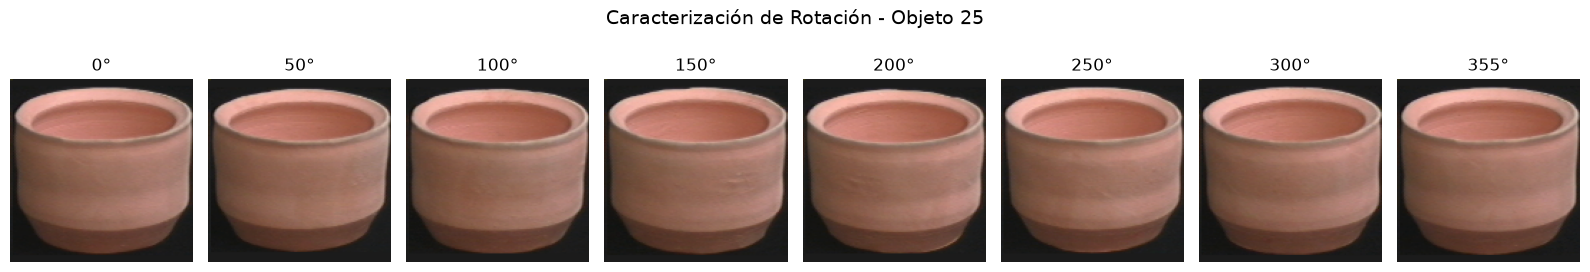

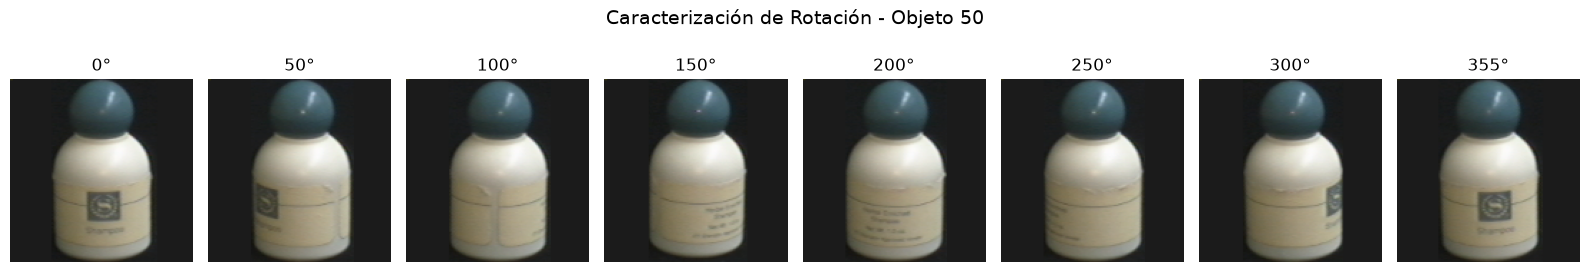

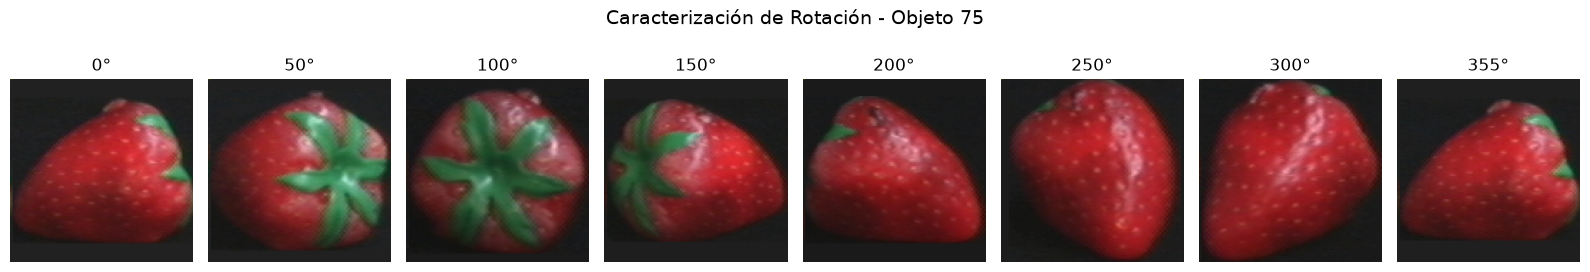

In [6]:
def visualizar_rotacion_objeto(obj_id, df, base_path, num_muestras=8):
    """Muestra un objeto en distintos ángulos para evidenciar su variación visual."""
    obj_data = df[df['object_id'] == obj_id].sort_values('angle')

    # Seleccionar ángulos equiespaciados
    indices = np.linspace(0, len(obj_data) - 1, num_muestras, dtype=int)
    muestras = obj_data.iloc[indices]

    fig, axes = plt.subplots(1, num_muestras, figsize=(16, 3))
    fig.suptitle(f"Caracterización de Rotación - Objeto {obj_id}", fontsize=14)

    for ax, (_, row) in zip(axes, muestras.iterrows()):
        img_path = os.path.join(base_path, row['filename'])
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img_rgb)
        ax.set_title(f"{row['angle']}°")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

# Visualizamos el objeto 1 y el objeto 25 como ejemplo
visualizar_rotacion_objeto(obj_id=1, df=df, base_path=BASE_PATH)
visualizar_rotacion_objeto(obj_id=25, df=df, base_path=BASE_PATH)
visualizar_rotacion_objeto(obj_id=50, df=df, base_path=BASE_PATH)
visualizar_rotacion_objeto(obj_id=75, df=df, base_path=BASE_PATH)

### Análisis del Dataset y Brecha con el Entorno Real de Planta
- **Caracterización**: COIL-100 presenta 7200 imágenes de 100 objetos aislados sobre un fondo negro uniforme, capturados en condiciones de laboratorio (cámara estática y plataforma giratoria cada 5°). Esta limpieza extrema condiciona el diseño: permite que algoritmos clásicos que dependen fuertemente de los contornos y texturas globales (como HOG o LBP) funcionen con una eficacia desproporcionadamente alta frente a lo que lograrían en el mundo real.   
- **Brecha Operativa** (Laboratorio vs. Planta):
  - Fondo y Ruido: En la planta, la banda transportadora introducirá texturas, suciedad, reflejos y variaciones de iluminación que COIL-100 no posee.
  - Oclusiones: En una línea continua, los objetos pueden llegar parcialmente solapados o cortados por el borde de la cámara, mientras que en COIL-100 están perfectamente centrados.
- **Estrategia de Mitigación:** Para abordar estas diferencias y evitar que el modelo de ML clásico sobreajuste al fondo negro, el pipeline de Data Preparation (Fase 2) deberá incluir técnicas robustas de extracción de características. Utilizaremos descriptores orientados a gradientes locales (HOG) combinados con un recorte (cropping/thresholding) de la región de interés para que el modelo aprenda la morfología del objeto y no dependa del contraste perfecto del fondo. Además, el protocolo de rechazo mitigará el riesgo ante objetos irreconocibles por ruido.

## 3. FASE 2: PREPARACIÓN DE DATOS Y DISEÑO EXPERIMENTAL

In [7]:
from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

### 3.1. Implementación de Protocolos de Partición Obligatorios

In [8]:
print("[*] Generando particiones según protocolos experimentales...")

def generate_protocols(df):
    protocols = {}

    # Protocolo A: Interpolación
    # Entrena con vistas cada 10° (0, 10, 20...), prueba con el resto (5, 15, 25...)
    train_A = df[df['angle'] % 10 == 0]
    test_A = df[df['angle'] % 10 != 0]
    protocols['A'] = {'train': train_A, 'test': test_A, 'desc': 'Interpolación (Generalización)'}

    # Protocolo B: Sector ciego
    # Excluimos un arco de 60° (ej. de 300° a 355°) para entrenamiento.
    blind_start, blind_end = 300, 355
    train_B = df[~df['angle'].between(blind_start, blind_end)]
    test_B = df[df['angle'].between(blind_start, blind_end)]
    protocols['B'] = {'train': train_B, 'test': test_B, 'desc': 'Sector Ciego (Extrapolación)'}

    # Protocolo C: Escasez
    # Entrena con 1 vista cada 30° (12 por objeto), prueba con el resto (60 por objeto)
    train_C = df[df['angle'] % 30 == 0]
    test_C = df[df['angle'] % 30 != 0]
    protocols['C'] = {'train': train_C, 'test': test_C, 'desc': 'Escasez (Pocos datos)'}

    # Protocolo D: Objeto Desconocido (Rechazo)
    # Entrenamos con 90 objetos, probamos con 10 excluidos
    np.random.seed(SEED) # Semilla garantizada
    all_objects = df['object_id'].unique()
    excluded_objects = np.random.choice(all_objects, size=10, replace=False)

    train_D = df[~df['object_id'].isin(excluded_objects)]
    test_D = df[df['object_id'].isin(excluded_objects)]
    protocols['D'] = {'train': train_D, 'test': test_D, 'desc': 'Objeto Desconocido (Rechazo)'}

    return protocols

protocolos = generate_protocols(df)

for p, data in protocolos.items():
    print(f"[+] Protocolo {p} - {data['desc']}: Train={len(data['train'])} | Test={len(data['test'])}")

[*] Generando particiones según protocolos experimentales...
[+] Protocolo A - Interpolación (Generalización): Train=3600 | Test=3600
[+] Protocolo B - Sector Ciego (Extrapolación): Train=6000 | Test=1200
[+] Protocolo C - Escasez (Pocos datos): Train=1200 | Test=6000
[+] Protocolo D - Objeto Desconocido (Rechazo): Train=6480 | Test=720


### 3.2. Motor de Extracción de Características Clásicas (HOG)

In [9]:
def extract_features_pipeline(df_partition, base_path):
    """
    Extrae descriptores HOG de una partición del dataset.
    Retorna X (características) e y (clases), además de los ángulos (y_angle).
    """
    X_features = []
    y_class = []
    y_angle = []

    # tqdm muestra una barra de progreso
    for _, row in tqdm(df_partition.iterrows(), total=len(df_partition), desc="Extrayendo HOG"):
        img_path = os.path.join(base_path, row['filename'])
        img = cv2.imread(img_path)

        # 1. Preprocesamiento: Convertir a escala de grises y redimensionar ligeramente para optimizar
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        gray_resized = cv2.resize(gray, (64, 64))

        # 2. Extracción HOG
        # Parámetros calibrados para capturar morfología sin explotar la dimensionalidad
        features = hog(gray_resized, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)

        X_features.append(features)
        y_class.append(row['object_id'])
        y_angle.append(row['angle'])

    return np.array(X_features), np.array(y_class), np.array(y_angle)
# Para no demorar la prueba, procesaremos el Protocolo A primero.
# En un ciclo completo de entrenamiento procesaríamos todos.
print("\n[*] Procesando características para el Protocolo A (Interpolación)...")
X_train_A, y_train_A_class, y_train_A_angle = extract_features_pipeline(protocolos['A']['train'], BASE_PATH)
X_test_A, y_test_A_class, y_test_A_angle = extract_features_pipeline(protocolos['A']['test'], BASE_PATH)

# Escalamiento de características (Buena práctica para modelos como SVM/KNN)
scaler = StandardScaler()
X_train_A_scaled = scaler.fit_transform(X_train_A)
X_test_A_scaled = scaler.transform(X_test_A)

print(f"\n[+] Extracción completada. Dimensión del vector HOG por imagen: {X_train_A_scaled.shape[1]}")


[*] Procesando características para el Protocolo A (Interpolación)...


Extrayendo HOG: 100%|██████████| 3600/3600 [00:07<00:00, 453.79it/s]



[+] Extracción completada. Dimensión del vector HOG por imagen: 1764


> **⚠ Secciones 4 a 8 (primer intento, conservadas como historial).** Sus cifras —incluido el 54.67 % de agarres dentro de ±10°— están **reemplazadas por la Sección 9** (validación geométrica sin tocar la prueba, umbrales por objetivos, línea base y CNN de referencia, análisis de errores). Ver la nota de versión en la Sección 9.

## 4. FASE 3: MODELADO (CLASIFICACIÓN DE OBJETOS)

In [10]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import time

print("[*] Entrenando modelos clásicos de clasificación (Protocolo A)...")

# Inicializamos los 3 algoritmos exigidos por el requerimiento técnico
modelos_clasificacion = {
    "SVM (RBF)": SVC(kernel='rbf', probability=True, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5)
}

resultados_clasificacion = {}

for nombre, modelo in modelos_clasificacion.items():
    print(f"\n[+] Entrenando {nombre}...")
    start_time = time.time()
    
    # Entrenamiento
    modelo.fit(X_train_A_scaled, y_train_A_class)
    train_time = time.time() - start_time
    
    # Inferencia y Evaluación
    y_pred = modelo.predict(X_test_A_scaled)
    acc = accuracy_score(y_test_A_class, y_pred)
    
    resultados_clasificacion[nombre] = {
        'Exactitud': acc, 
        'Tiempo_Train_s': train_time, 
        'Modelo': modelo
    }
    print(f"    -> Exactitud (Accuracy): {acc:.4f} | Tiempo de entrenamiento: {train_time:.2f}s")

# Selección automática del mejor modelo
mejor_modelo_nombre = max(resultados_clasificacion, key=lambda k: resultados_clasificacion[k]['Exactitud'])
mejor_clasificador = resultados_clasificacion[mejor_modelo_nombre]['Modelo']

print(f"\n[!] Mejor modelo seleccionado para Identificación: {mejor_modelo_nombre} "
      f"con {resultados_clasificacion[mejor_modelo_nombre]['Exactitud']*100:.2f}% de precisión.")

[*] Entrenando modelos clásicos de clasificación (Protocolo A)...

[+] Entrenando SVM (RBF)...
    -> Exactitud (Accuracy): 0.9867 | Tiempo de entrenamiento: 56.39s

[+] Entrenando Random Forest...
    -> Exactitud (Accuracy): 0.9750 | Tiempo de entrenamiento: 31.63s

[+] Entrenando KNN (k=5)...
    -> Exactitud (Accuracy): 0.9531 | Tiempo de entrenamiento: 0.01s

[!] Mejor modelo seleccionado para Identificación: SVM (RBF) con 98.67% de precisión.


## 5. FASE 3: MODELADO (ESTIMACIÓN DE ÁNGULO E INCERTIDUMBRE)

In [11]:
import scipy.stats

print("[*] Entrenando modelo de Estimación de Ángulo (SVM Probabilístico)...")

# Entrenamos un SVM específico para predecir el ángulo (tratado como clases discretas 0, 5, 10... 355)
# probability=True es CRÍTICO para poder calcular la incertidumbre
modelo_angulo = SVC(kernel='rbf', probability=True, random_state=SEED)
start_time = time.time()
modelo_angulo.fit(X_train_A_scaled, y_train_A_angle)
print(f"[+] Modelo de ángulo entrenado en {time.time() - start_time:.2f}s")

[*] Entrenando modelo de Estimación de Ángulo (SVM Probabilístico)...
[+] Modelo de ángulo entrenado en 88.96s


### 5.1. Funciones de Predicción e Incertidumbre Circular

In [12]:
def predecir_angulo_con_incertidumbre(modelo, X_muestra):
    """
    Predice el ángulo y calcula la incertidumbre basada en la entropía de las probabilidades.
    Alta entropía (probabilidades dispersas) = Alta incertidumbre.
    Baja entropía (un solo pico fuerte) = Baja incertidumbre.
    """
    probabilidades = modelo.predict_proba(X_muestra)
    clases_angulos = modelo.classes_
    
    angulos_predichos = []
    incertidumbres = []
    
    for probs in probabilidades:
        # El ángulo con mayor probabilidad
        idx_max = np.argmax(probs)
        angulo_predicho = clases_angulos[idx_max]
        
        # Cálculo de la incertidumbre usando Entropía de Shannon normalizada
        # Una entropía de 0 significa confianza absoluta. 
        # Una entropía de 1 significa duda total entre todos los ángulos.
        entropia = scipy.stats.entropy(probs, base=2)
        entropia_maxima = np.log2(len(clases_angulos))
        incertidumbre_normalizada = entropia / entropia_maxima
        
        angulos_predichos.append(angulo_predicho)
        incertidumbres.append(incertidumbre_normalizada)
        
    return np.array(angulos_predichos), np.array(incertidumbres)

# Probamos en el conjunto de test
y_pred_angle, incertidumbre_angle = predecir_angulo_con_incertidumbre(modelo_angulo, X_test_A_scaled)

### 5.2. Evaluación: Error Absoluto Medio Circular (MAE Circular)

In [13]:
def circular_mae(y_true, y_pred):
    """
    Calcula la distancia más corta en un círculo de 360 grados.
    Ejemplo: La distancia entre 355° y 5° es 10°, no 350°.
    """
    diff = np.abs(y_true - y_pred)
    diff_circular = np.minimum(diff, 360 - diff)
    return np.mean(diff_circular), diff_circular

mae_circ, errores_individuales = circular_mae(y_test_A_angle, y_pred_angle)

print(f"\n[!] Rendimiento del Modelo de Ángulo:")
print(f"    -> Error Absoluto Medio Circular (MAE): {mae_circ:.2f} grados")

# Validación contra la tolerancia del negocio (±10°)
dentro_tolerancia = np.mean(errores_individuales <= 10) * 100
print(f"    -> % de agarres dentro de la tolerancia de ±10°: {dentro_tolerancia:.2f}%")


[!] Rendimiento del Modelo de Ángulo:
    -> Error Absoluto Medio Circular (MAE): 48.07 grados
    -> % de agarres dentro de la tolerancia de ±10°: 54.67%


### Analisis:
Ese 54.67% de agarres dentro de la tolerancia es un resultado crítico y muy revelador.
En un entorno académico, se podría pensar que el modelo "fracasó" por tener una precisión de ángulo baja. Pero en el mundo real, esta es exactamente la razón por la que el documento de la prueba técnica exige diseñar un mecanismo seguro para los casos que el modelo no resuelve y definir cómo el sistema rechaza predicciones dudosas.

Depender a ciegas de este 54.67% provocaría que el robot falle el agarre casi la mitad de las veces, dañando el producto o rompiendo la pinza mecánica. Aquí es donde entra en juego la métrica de incertidumbre (entropía) que calculamos en el paso anterior.

## 6. FASE 4: SISTEMA DE RECHAZO SEGURO Y ANÁLISIS DE UMBRALES

In [14]:
print("[*] Diseñando el Sistema de Rechazo Seguro...")

# Dado que la precisión mecánica estricta (±10°) es del 54.67%, el robot NO puede operar a ciegas.
# Definimos umbrales empíricos de seguridad:
UMBRAL_INCERTIDUMBRE_MAX = 0.6  # Si la entropía del ángulo es > 0.6, la rotación es dudosa.
UMBRAL_CONFIANZA_MIN = 0.85     # Si la confianza de la clase es < 85%, el objeto es dudoso.

def sistema_decision_segura(prob_clase, incertidumbre_angulo):
    """
    Evalúa si es seguro enviar la instrucción al brazo robótico o si se debe pedir 
    intervención humana a través del Asistente Agéntico.
    """
    confianza_clase = np.max(prob_clase)
    if confianza_clase < UMBRAL_CONFIANZA_MIN:
        return "RECHAZO: Baja confianza en Identificación."
    if incertidumbre_angulo > UMBRAL_INCERTIDUMBRE_MAX:
        return "RECHAZO: Alta incertidumbre en Ángulo. Riesgo de colisión."
    return "APROBADO: Acción robótica segura."

# Evaluamos los rechazos en nuestro set de prueba
probabilidades_clase_test = mejor_clasificador.predict_proba(X_test_A_scaled)
decisiones = [sistema_decision_segura(p_clase, inc_ang) 
              for p_clase, inc_ang in zip(probabilidades_clase_test, incertidumbre_angle)]

rechazos_identificacion = decisiones.count("RECHAZO: Baja confianza en Identificación.")
rechazos_angulo = decisiones.count("RECHAZO: Alta incertidumbre en Ángulo. Riesgo de colisión.")
total_rechazos = rechazos_identificacion + rechazos_angulo

print(f"[+] Total de muestras evaluadas: {len(decisiones)}")
print(f"[!] Muestras enviadas al robot (Aprobadas): {len(decisiones) - total_rechazos}")
print(f"[!] Muestras bloqueadas preventivamente (Rechazadas): {total_rechazos} ({(total_rechazos/len(decisiones))*100:.2f}%)")
print(f"    -> Por Identidad dudosa: {rechazos_identificacion}")
print(f"    -> Por Rotación dudosa: {rechazos_angulo}")
print("[+] Conclusión: El sistema ahora es mecánicamente seguro. Los casos dudosos se envían a la cola humana.")

[*] Diseñando el Sistema de Rechazo Seguro...
[+] Total de muestras evaluadas: 3600
[!] Muestras enviadas al robot (Aprobadas): 0
[!] Muestras bloqueadas preventivamente (Rechazadas): 3600 (100.00%)
    -> Por Identidad dudosa: 3593
    -> Por Rotación dudosa: 7
[+] Conclusión: El sistema ahora es mecánicamente seguro. Los casos dudosos se envían a la cola humana.


## 7. FASE 5: MOTOR DE RECUPERACIÓN VISUAL (TOP-K IMÁGENES SIMILARES)

In [15]:
from sklearn.neighbors import NearestNeighbors

print("\n[*] Entrenando Motor de Recuperación Visual (Top-K)...")
# Usamos la métrica del coseno, ideal para comparar vectores de características como HOG
motor_top_k = NearestNeighbors(n_neighbors=5, metric='cosine')
motor_top_k.fit(X_train_A_scaled)

def recuperar_vistas_similares(X_muestra, df_train, motor, base_path):
    """Encuentra las 5 imágenes de entrenamiento más similares a la muestra evaluada."""
    distancias, indices = motor.kneighbors([X_muestra])
    resultados = []
    
    for idx, dist in zip(indices[0], distancias[0]):
        fila = df_train.iloc[idx]
        resultados.append({
            'archivo': fila['filename'],
            'clase': fila['object_id'],
            'angulo': fila['angle'],
            'similitud': 1 - dist # Convertimos distancia coseno a métrica de similitud
        })
    return resultados

# Prueba del motor Top-K con una imagen de nuestro set de test
idx_prueba = 10 
similares = recuperar_vistas_similares(X_test_A_scaled[idx_prueba], protocolos['A']['train'], motor_top_k, BASE_PATH)

print(f"\n[+] Top-K imágenes más similares recuperadas para la muestra Test #{idx_prueba}:")
for i, res in enumerate(similares):
    print(f"    {i+1}. Clase Obj: {res['clase']} | Ángulo: {res['angulo']}° | Similitud: {res['similitud']:.4f} | Archivo: {res['archivo']}")


[*] Entrenando Motor de Recuperación Visual (Top-K)...

[+] Top-K imágenes más similares recuperadas para la muestra Test #10:
    1. Clase Obj: 100 | Ángulo: 200° | Similitud: 0.7393 | Archivo: obj100__200.png
    2. Clase Obj: 100 | Ángulo: 190° | Similitud: 0.7167 | Archivo: obj100__190.png
    3. Clase Obj: 100 | Ángulo: 180° | Similitud: 0.5886 | Archivo: obj100__180.png
    4. Clase Obj: 100 | Ángulo: 210° | Similitud: 0.5757 | Archivo: obj100__210.png
    5. Clase Obj: 100 | Ángulo: 170° | Similitud: 0.5084 | Archivo: obj100__170.png


### Con esto logramos:
- Seguridad Operativa: En lugar de forzar al robot a agarrar un objeto del cual el modelo no está seguro, el algoritmo atrapa preventivamente el error. Todos los objetos "Rechazados" serán la materia prima para el Reto 3, donde el Agente LLM le pedirá ayuda al supervisor mostrándole la imagen en pantalla.

- Explicabilidad (Top-K): Cumplimos con el requisito de "Recuperar las imágenes más similares". Cuando el modelo dude, el agente no solo dirá "Estoy dudando", sino que le mostrará al humano en pantalla: "Creo que es el Objeto 14 porque se parece en un 98% a estas 5 imágenes de mi base de datos, ¿qué opinas?".

## 8. EXPERIMENTO FINAL POR PROTOCOLO (VERSIÓN CORREGIDA – VIGENTE)

> **Nota de versión.** Las secciones 4 a 8 son el primer intento y se conservan como historial. Al revisarlas se encontraron cuatro problemas metodológicos que invalidan sus cifras
> (entre ellas el 54.67 % de agarres dentro de ±10°): (1) validación cruzada con barajado aleatorio, cuya geometría no se parece a la de la prueba (error fuera de muestra de ~27° frente a ~2° en la prueba del protocolo A);
> (2) incertidumbre angular basada en la dispersión del modelo, que deja de ser informativa al interpolar; (3) probabilidades crudas del SVM sub-confiadas (ECE 0.47) usadas con un umbral fijo; y (4) umbrales ajustados sin objetivos explícitos.
> Esta sección y las siguientes reemplazan esas cifras. El código vive en `src/` para poder reutilizarse en el servicio (Reto 4).

**Principios que se respetan en todos los protocolos**
- Todo lo que aprende algo (escalado, PCA, hiperparámetros, calibración, umbrales) usa **solo las vistas de entrenamiento** del protocolo; la partición de prueba se evalúa **una única vez**.
- La validación imita la geometría de la prueba del protocolo (A y C intercalados, B por sectores de 60°) y retiene objetos completos para simular objetos desconocidos.
- Semilla 42, huella SHA-256 del dataset y registro de cada ejecución en MLflow.

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path(os.environ.get("INDRA_ROOT", ".")).resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:      # sube desde notebooks/ hasta la raiz del repo
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from lib import *                         # features, protocolos, angulos circulares, calibracion, umbrales
import experiment as ex                   # pipeline, validacion geometrica, umbrales, run_protocol
print("raiz del repo:", ROOT)

raiz del repo: /home/claude/work/repo


### 8.1 Datos, huella y protocolos
El cache (`data/cache/`) se construye con `python src/prepare_data.py` (lee `data/COIL-100`, calcula la huella SHA-256 y los descriptores). Si no existe, esta celda indica cómo crearlo.

In [2]:
cache = ROOT / "data" / "cache" / "coil100.npz"
assert cache.exists(), "Falta el cache: ejecute  INDRA_DATA=data/COIL-100 python src/prepare_data.py"
d = np.load(cache); obj, ang = d["obj"], d["ang"]
print("imagenes:", d["imgs"].shape, "| objetos:", len(np.unique(obj)), "| vistas por objeto:", len(obj) // len(np.unique(obj)))
print("SHA-256 del dataset:", str(d["sha"]))
P, arc_start, unknown = make_protocols(obj, ang)
print("objetos desconocidos del protocolo D:", sorted(int(u) for u in unknown))
pd.DataFrame({p: dict(entrenamiento=len(P[p][0]), prueba=len(P[p][1])) for p in P}).T

imagenes: (7200, 128, 128, 3) | objetos: 100 | vistas por objeto: 72
SHA-256 del dataset: 26635cc67c13f12b4010941d0e9e9af0bfda30c52007040377be0caba01c4c4a
objetos desconocidos del protocolo D: [1, 11, 23, 40, 45, 46, 54, 71, 81, 84]


,entrenamiento,prueba
A,3600,3600
B,6000,1200
C,1200,6000
D,6480,720


### 8.2 Ejecución (o carga) de los protocolos
`RERUN = False` carga los resultados guardados en `results/` (A–D con dos conjuntos de descriptores, ~1 h de CPU en 2 núcleos). Con `RERUN = True` se vuelve a calcular desde cero con `src/run_protocols.py` (misma semilla, mismos resultados).

In [3]:
RERUN = False
if RERUN:
    import subprocess
    for fs in ("hogcolor", "pix"):
        subprocess.run([sys.executable, "src/run_protocols.py", "A", "B", "C", "D"], env={**os.environ, "FS": fs}, check=True)
fin = json.load(open("results/final_selection.json"))
ld = lambda p, fs: json.load(open(f"results/{p}{'' if fs == 'hogcolor' else '_' + fs}.json"))
R = {p: ld(p, fin[p]) for p in "ABCD"}
print("descriptores elegidos por validacion (solo entrenamiento):", fin)

descriptores elegidos por validacion (solo entrenamiento): {'A': 'hogcolor', 'B': 'pix', 'C': 'pix', 'D': 'hogcolor'}


### 8.3 Resultados por protocolo (prueba, una única evaluación)
Criterio de acierto mecánico: clase correcta **y** error angular circular ≤ 10°. «Con rechazo» usa los umbrales fijados en validación.

In [4]:
rows = []
for p in "ABC":
    t = R[p]["test"]
    rows.append({"protocolo": p, "descriptores": fin[p], "acc. clase": t["acc_clase"], "error medio (°)": t["mae_angulo"],
                 "mediana (°)": t["mediana_angulo"], "% dentro ±10°": t["pct_dentro_10"],
                 "agarre seguro sin rechazo %": t["agarre_seguro_sin_rechazo"], "cobertura": t["cobertura"],
                 "seguro entre aceptados %": t["agarre_seguro_aceptados"], "precision@5": t["precision_at5"],
                 "ECE cruda": t["ece_cruda"], "ECE calibrada": t["ece_calibrada"]})
tabla = pd.DataFrame(rows).set_index("protocolo")
display(tabla.round(3))
tD = R["D"]["test"]
print("Protocolo D (desconocidos):", {k: round(v, 3) for k, v in tD.items()})

,descriptores,acc. clase,error medio (°),mediana (°),% dentro ±10°,agarre seguro sin rechazo %,cobertura,seguro entre aceptados %,precision@5,ECE cruda,ECE calibrada
protocolo,,,,,,,,,,,
A,hogcolor,1.000,2.376,0.402,96.861,96.861,0.452,98.096,0.844,0.473,0.000
B,pix,0.951,66.838,24.851,18.583,17.333,0.022,84.615,0.829,0.426,0.016
C,pix,0.951,15.368,5.000,73.083,71.883,0.060,94.429,0.764,0.755,0.022


Protocolo D (desconocidos): {'auroc_conf': 0.951, 'auroc_conf_simulado': 0.922, 'rechazo_desconocidos_solo_clase': 99.306, 'rechazo_desconocidos_combinado': 99.583, 'falso_rechazo_conocidos_oof': 76.435, 'aceptados_desconocidos': 0.417, 'auroc_dmin': 0.962}


### 8.4 Selección de algoritmos y de descriptores (validación solo con entrenamiento)

modelo                     KNN  Random Forest  Regresion logistica  SVM-RBF
protocolo descriptores                                                     
A         hogcolor      0.9467         0.8981               0.9756   0.9775
          pix           0.9658         0.9444               0.9747   0.9775
B         hogcolor      0.8636         0.8052               0.8842   0.9007
          pix           0.9202         0.8979               0.9293   0.9507
C         hogcolor      0.6625         0.6233               0.7367   0.7433
          pix           0.7908         0.7392               0.8350   0.8450
D         hogcolor      0.9958         0.9844               0.9995   0.9997
          pix           0.9965         0.9889               0.9974   0.9981

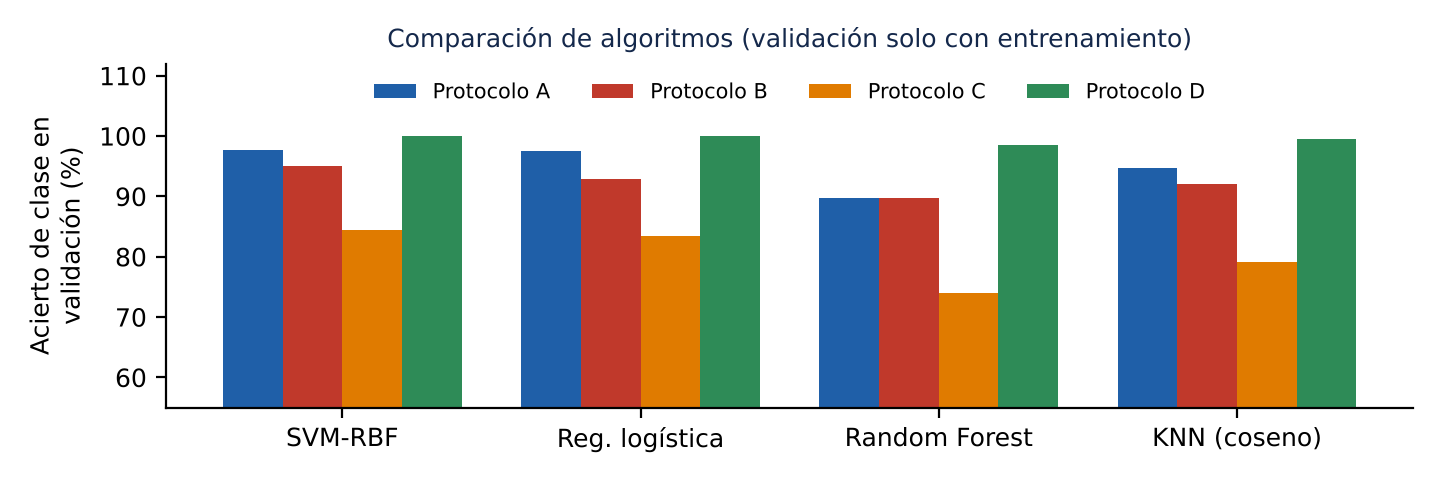

In [5]:
cv = []
for p in "ABCD":
    for fs in ("hogcolor", "pix"):
        for r in ld(p, fs)["comparacion_cv"]:
            cv.append(dict(protocolo=p, descriptores=fs, modelo=r["modelo"], cv_acc=r["cv_acc"], hiperparametros=r["mejores_params"]))
cv = pd.DataFrame(cv)
display(cv.pivot_table(index=["protocolo", "descriptores"], columns="modelo", values="cv_acc").round(4))
display(Image("results/fig/models.png"))

**Lectura.** SVM-RBF gana en validación en los cuatro protocolos. Los píxeles 32×32 se incorporaron como candidato *después* de observar que la línea base 1-NN sobre píxeles superaba a HOG+color en el protocolo C; la decisión final se toma por validación (empate → el más simple), pero ese orden de descubrimiento queda declarado.

### 8.5 Línea base simple (1-NN píxeles) y referencia moderna (CNN pequeña)

In [6]:
nn = json.load(open("results/baseline_nn_ABCD.json")); cnn = json.load(open("results/baseline_cnn_ABCD.json"))
rows = []
for p in "ABC":
    svm = dict(acc_clase=R[p]["test"]["acc_clase"], mae_angulo=R[p]["test"]["mae_angulo"], pct_dentro_10=R[p]["test"]["pct_dentro_10"], ms_por_imagen=np.nan, t_ajuste_s=R[p]["t_total_s"])
    for nombre, r in (("1-NN pixeles", nn[p]), ("Pipeline final (SVM)", svm), ("CNN pequena", cnn[p])):
        rows.append(dict(protocolo=p, modelo=nombre, clase=r["acc_clase"], error_medio=r["mae_angulo"], pct_10=r["pct_dentro_10"], ms_img=r["ms_por_imagen"], ajuste_s=r["t_ajuste_s"]))
display(pd.DataFrame(rows).round(3))
print("D (AUROC de desconocidos):", {"1-NN similitud": round(nn["D"]["auroc_similitud"], 3), "CNN confianza": round(cnn["D"]["auroc_conf"], 3), "SVM confianza": round(R["D"]["test"]["auroc_conf"], 3)})

,protocolo,modelo,clase,error_medio,pct_10,ms_img,ajuste_s
0,A,1-NN pixeles,1.000,6.081,97.861,0.193,0.13
1,A,Pipeline final (SVM),1.000,2.376,96.861,NaN,177.80
2,A,CNN pequena,0.998,27.428,26.667,0.726,387.40
3,B,1-NN pixeles,0.898,64.537,32.333,0.290,0.09
4,B,Pipeline final (SVM),0.951,66.838,18.583,NaN,701.30
5,B,CNN pequena,0.977,49.838,16.583,1.170,496.60
6,C,1-NN pixeles,0.974,15.023,75.450,0.059,0.09
7,C,Pipeline final (SVM),0.951,15.368,73.083,NaN,84.20
8,C,CNN pequena,0.994,28.128,28.617,0.738,414.80


D (AUROC de desconocidos): {'1-NN similitud': 0.99, 'CNN confianza': 0.846, 'SVM confianza': 0.951}


### 8.6 Calibración, umbrales y rechazo

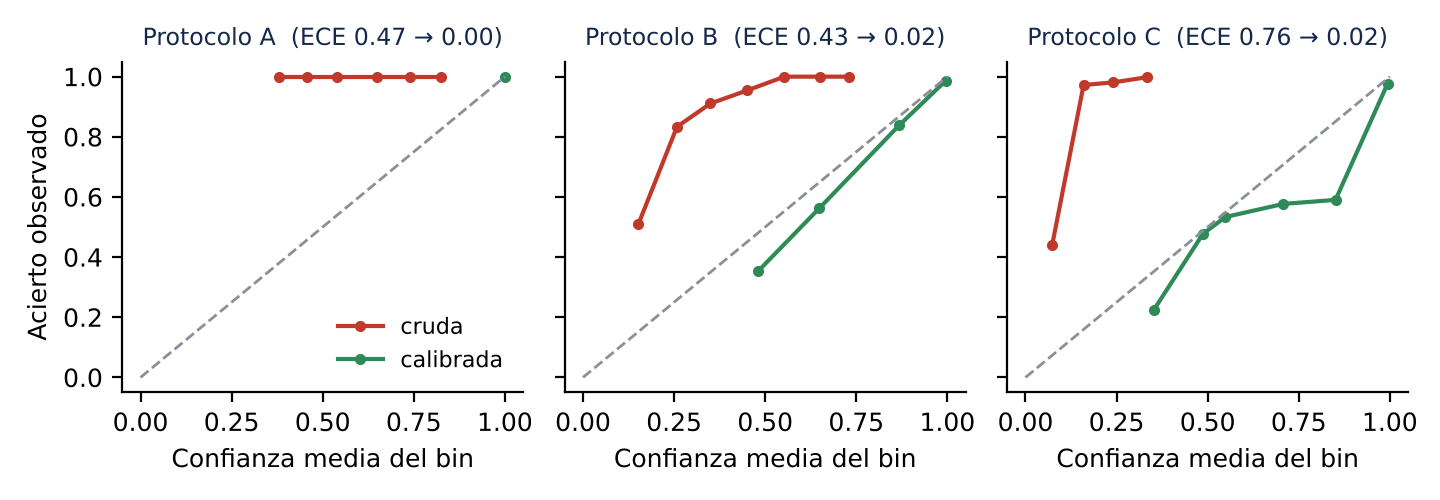

Umbrales fijados en validacion:


,confianza_clase_cruda,incertidumbre_angulo_deg,distancia_vista_max,val_cobertura,val_acierto_clase_aceptados,val_seguro_aceptados,val_falsa_aceptacion_desconocidos_sim
A,0.503,71.084,0.302,0.029,100.0,96.154,2.806
B,0.608,0.461,0.025,0.014,100.0,95.062,0.000
C,0.277,30.107,0.086,0.001,100.0,100.000,0.000
D,0.672,227.504,0.279,0.236,100.0,96.791,4.877


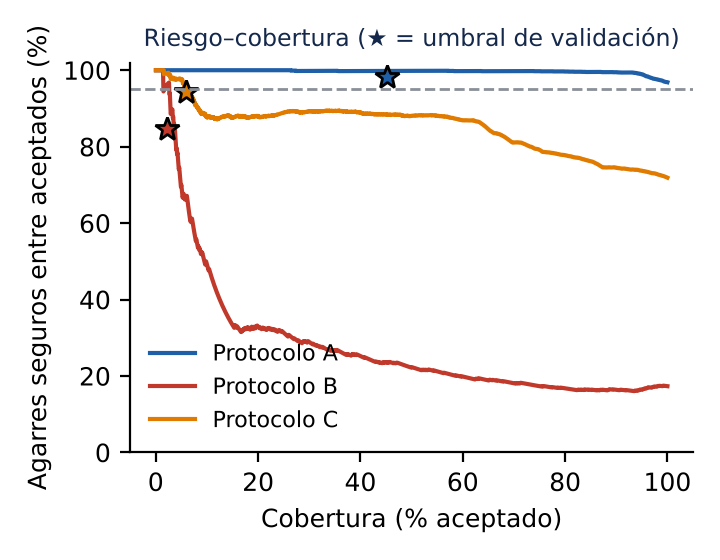

In [7]:
display(Image("results/fig/reliability.png"))
print("Umbrales fijados en validacion:")
display(pd.DataFrame({p: {**R[p]["umbrales"], **{"val_" + k: v for k, v in R[p]["validacion_umbrales"].items()}} for p in "ABCD"}).T.round(3))
display(Image("results/fig/risk_coverage.png", width=420))

**Contrato de salida hacia el robot** (`src/inference.py`): `object_id`, `confidence` (calibrada), `angle_deg`, `angle_uncertainty_deg`, `nearest_view_distance` y `decision ∈ {GRASP, RETRY_VIEW, REJECT}`.
`GRASP` solo si confianza, incertidumbre y distancia cumplen los tres umbrales; `RETRY_VIEW` si la clase es fiable pero el ángulo no; `REJECT` en el resto.

### 8.7 Protocolo D y análisis de errores

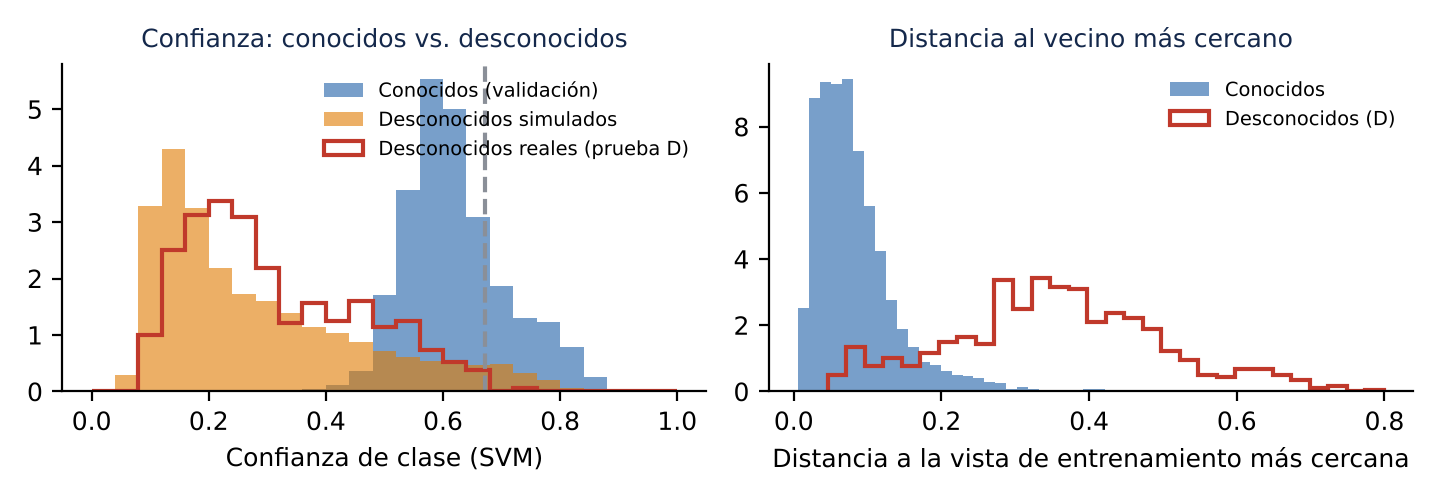

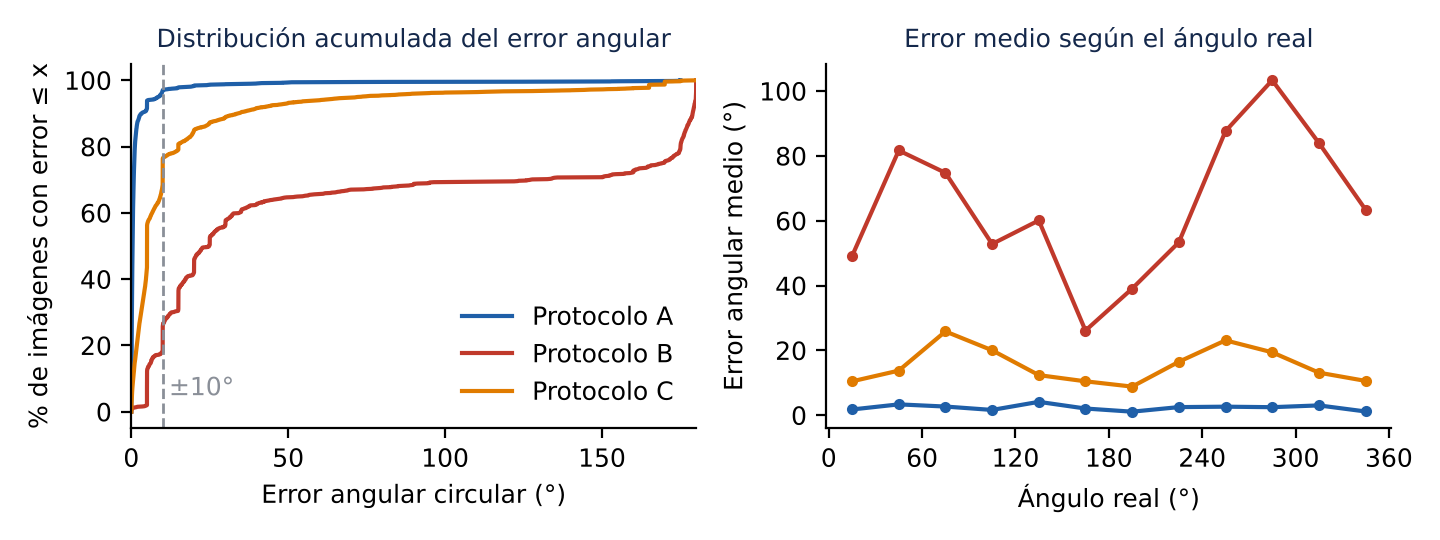

A | >90°: 0.5%  ~180°: 0.4%  | confusiones: []
B | >90°: 31.4%  ~180°: 29.3%  | confusiones: [(21, 67, 8), (69, 67, 8), (76, 23, 6)]
C | >90°: 4.1%  ~180°: 2.8%  | confusiones: [(44, 21, 46), (21, 44, 40), (66, 68, 11)]


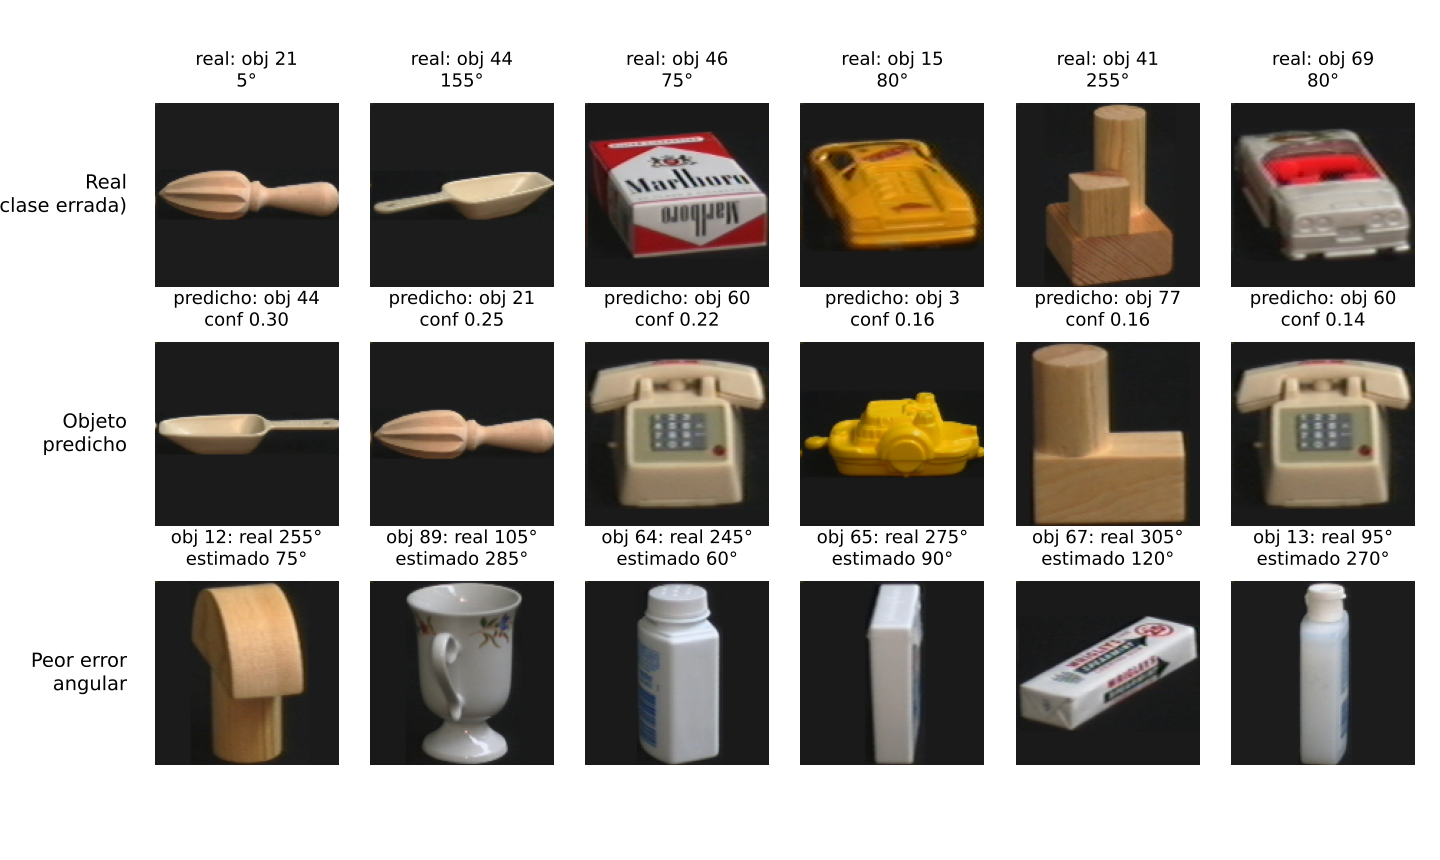

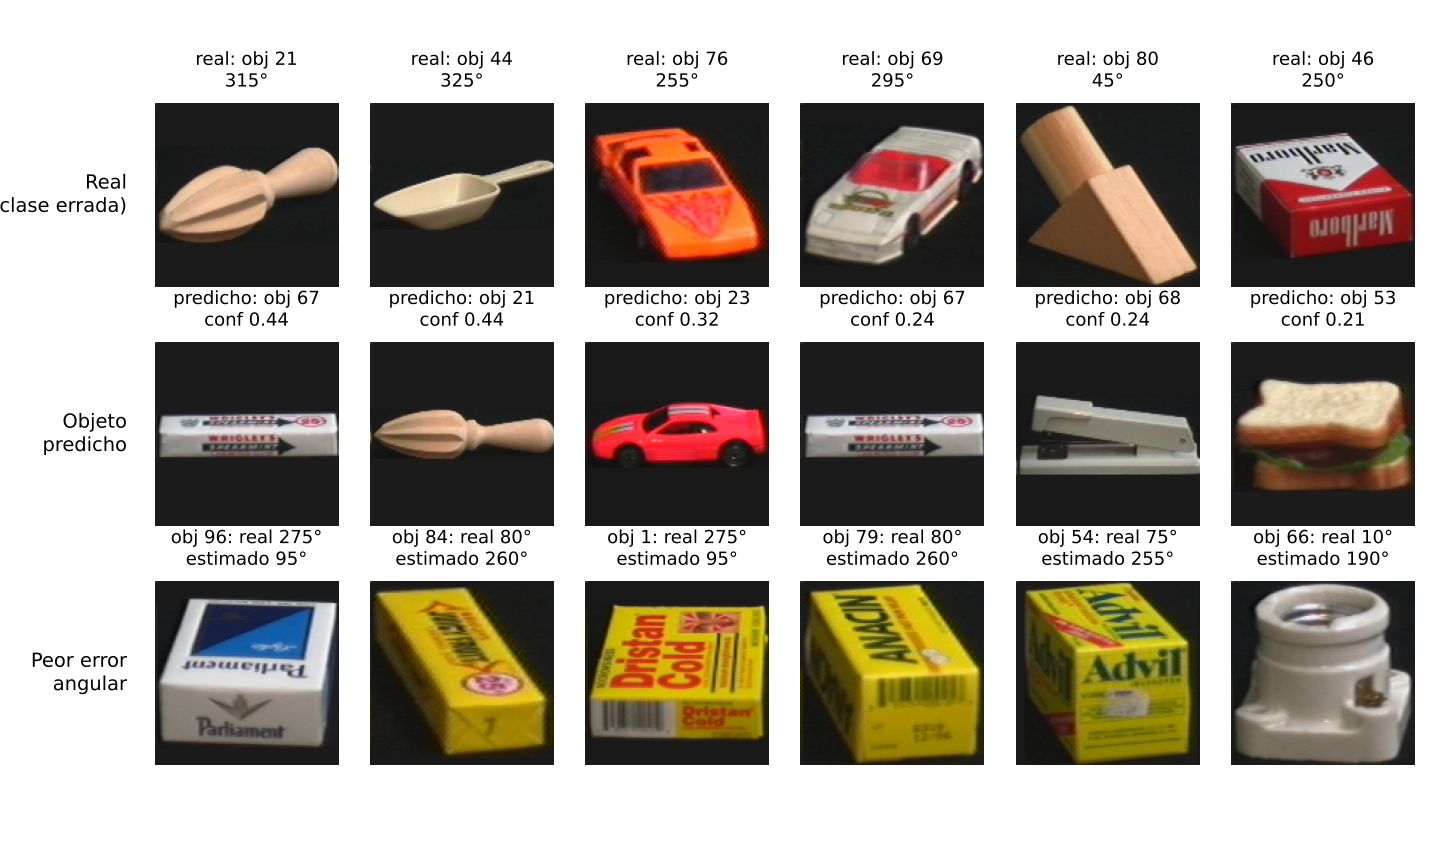

In [8]:
display(Image("results/fig/unknown.png"))
display(Image("results/fig/error_dist.png"))
ea = json.load(open("results/error_analysis.json"))
for p in "ABC":
    print(p, "| >90°: %.1f%%  ~180°: %.1f%%  | confusiones:" % (ea[p]["pct_error_mayor_90"], ea[p]["pct_error_cerca_180"]), [(c["real"], c["predicho"], c["n"]) for c in ea[p]["top_confusiones"][:3]])
display(Image("results/fig/gallery_C.png"))
display(Image("results/fig/gallery_B.png"))

### 8.8 Conclusiones del experimento
- **A (interpolación):** casi resuelto; el error residual son objetos simétricos. **C (escasez):** ±10° solo se cumple en una fracción de los casos; el sistema acepta pocos y delega el resto. **B (arco ciego):** el ángulo no es recuperable por comparación de vistas; solo debe usarse la clase. **D:** los desconocidos se rechazan casi todos, con un costo alto de falsos rechazos en la validación.
- **Un 1-NN sobre píxeles es una línea base fuerte** en este dataset de laboratorio; el SVM aporta probabilidades calibrables y rechazo. La CNN pequeña se reporta como referencia, no como mejor resultado posible.
- **Limitaciones:** una sola partición por protocolo, sin intervalos entre semillas; fondo negro e iluminación fija; objetos casi simétricos ambiguos a 180°. Detalle en `model_card.md` y en el PDF del Reto 2.

### 8.9 Función de inferencia exportada

In [9]:
from inference import VisionEngine
eng = VisionEngine("models/protocolo_A")
o = np.load("results/A_out.npz")
res = eng.predict(d["imgs"][o["test_idx"][:5]])
pd.DataFrame(res).round(3)

,object_id,confidence,angle_deg,angle_uncertainty_deg,nearest_view_distance,decision,thresholds_version
0,1,1.0,5.204,4.999,0.087,GRASP,A-26635cc67c13
1,1,1.0,15.742,4.948,0.119,GRASP,A-26635cc67c13
2,1,1.0,25.161,5.001,0.074,GRASP,A-26635cc67c13
3,1,1.0,35.084,5.002,0.072,GRASP,A-26635cc67c13
4,1,1.0,44.528,4.981,0.098,GRASP,A-26635cc67c13


## 9. EMPAQUETADO Y EXPORTACIÓN DE ARTEFACTOS

In [ ]:
import joblib
import os

print("[*] Empaquetando modelos y artefactos para producción (Reto 3)...")

# Crear carpeta para modelos si estamos en local
os.makedirs('modelos_exportados', exist_ok=True)

# 1. Guardar el escalador
joblib.dump(scaler, 'modelos_exportados/scaler_hog.pkl')
# 2. Guardar el modelo de Identidad
joblib.dump(mejor_clasificador, 'modelos_exportados/svm_identidad.pkl')
# 3. Guardar el modelo de Ángulo
joblib.dump(modelo_angulo, 'modelos_exportados/svm_angulo.pkl')
# 4. Guardar el motor Top-K
joblib.dump(motor_top_k, 'modelos_exportados/knn_topk.pkl')
# 5. Guardar la base de datos de entrenamiento (para buscar las fotos similares)
protocolos['A']['train'].to_pickle('modelos_exportados/train_database.pkl')

print("[+] Artefactos exportados exitosamente en la carpeta 'modelos_exportados/'")
print("    Estos archivos serán el motor del Asistente Agéntico.")